In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# [DEMO] Bài 1: Phát hiện Tấn công ICS bằng Học máy Có Giám sát

> **File này là bản DEMO hoàn chỉnh** — tất cả code đã được điền sẵn và có thể chạy ngay.
> Học viên hãy chạy từng cell theo thứ tự, quan sát kết quả, rồi tự thực hành trong file `b1_ml_batadal_exercise.ipynb`.

## Mục tiêu
- Xây dựng mô hình học máy **có giám sát** để phân loại tấn công/bình thường trong hệ thống ICS
- So sánh 3 thuật toán: **Logistic Regression**, **Random Forest**, **Gradient Boosting**
- Phân tích **tầm quan trọng đặc trưng** (Feature Importance) để hiểu cảm biến nào quan trọng nhất
- Đánh giá khả năng tổng quát hóa trên tập test độc lập

## Phần 1: Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score,
                              confusion_matrix, roc_auc_score, roc_curve,
                              ConfusionMatrixDisplay)
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.rcParams['figure.figsize'] = (13, 5)
print('Thư viện đã được import thành công!')

Thư viện đã được import thành công!


## Phần 2: Tải và Khám phá Dữ liệu

In [2]:
train_df = pd.read_csv('data/BATADAL/train_dataset.csv', index_col=0)
test1_df = pd.read_csv('data/BATADAL/test_dataset_1.csv', index_col=0)
test2_df = pd.read_csv('data/BATADAL/test_dataset_2.csv', index_col=0)

feature_cols  = [c for c in train_df.columns if c not in ['DATETIME', 'ATT_FLAG']]
pressure_cols = [c for c in feature_cols if 'PRESSURE' in c]
flow_cols     = [c for c in feature_cols if 'FLOW' in c]
status_cols   = [c for c in feature_cols if 'STATUS' in c]

print(f'Train : {train_df.shape[0]:>6} mẫu × {train_df.shape[1]} cột (chỉ dữ liệu bình thường)')
print(f'Test 1: {test1_df.shape[0]:>6} mẫu × {test1_df.shape[1]} cột (có nhãn tấn công)')
print(f'Test 2: {test2_df.shape[0]:>6} mẫu × {test2_df.shape[1]} cột (tập kiểm tra cuối)')
print(f'\nSố đặc trưng: {len(feature_cols)} '
      f'(áp suất={len(pressure_cols)}, lưu lượng={len(flow_cols)}, trạng thái={len(status_cols)})')
print(f'\nPhân phối nhãn trong Test 1:')
print(f'  Bình thường: {(test1_df.ATT_FLAG==0).sum()} ({100*(test1_df.ATT_FLAG==0).mean():.1f}%)')
print(f'  Tấn công   : {(test1_df.ATT_FLAG==1).sum()} ({100*(test1_df.ATT_FLAG==1).mean():.1f}%)')

Train :  48106 mẫu × 45 cột (chỉ dữ liệu bình thường)
Test 1:  18433 mẫu × 45 cột (có nhãn tấn công)
Test 2:  10081 mẫu × 45 cột (tập kiểm tra cuối)

Số đặc trưng: 43 (áp suất=19, lưu lượng=12, trạng thái=12)

Phân phối nhãn trong Test 1:
  Bình thường: 16465 (89.3%)
  Tấn công   : 1968 (10.7%)


## Phần 3: Chuẩn bị Dữ liệu cho Học máy Có Giám sát

**Chiến lược:** Dùng `test_dataset_1.csv` (có nhãn ATT_FLAG) làm tập dữ liệu huấn luyện.
Chia 70/30 cho train/val, dùng `test_dataset_2.csv` làm tập test cuối cùng (held-out).

In [3]:
X_sup = test1_df[feature_cols].values
y_sup = test1_df['ATT_FLAG'].values

scaler = StandardScaler()
X_sup_scaled   = scaler.fit_transform(X_sup)
X_test2_scaled = scaler.transform(test2_df[feature_cols].values)
y_test2        = test2_df['ATT_FLAG'].values

X_tr, X_val, y_tr, y_val = train_test_split(
    X_sup_scaled, y_sup, test_size=0.3, random_state=42, stratify=y_sup
)

print(f'Tập huấn luyện : {X_tr.shape[0]:>6} mẫu  '
      f'(Normal={(y_tr==0).sum()}, Attack={(y_tr==1).sum()})')
print(f'Tập validation : {X_val.shape[0]:>6} mẫu  '
      f'(Normal={(y_val==0).sum()}, Attack={(y_val==1).sum()})')
print(f'Tập test cuối  : {X_test2_scaled.shape[0]:>6} mẫu  '
      f'(Normal={(y_test2==0).sum()}, Attack={(y_test2==1).sum()})')
print(f'\nTỷ lệ tấn công trong train: {y_tr.mean()*100:.1f}%')

Tập huấn luyện :  12903 mẫu  (Normal=11525, Attack=1378)
Tập validation :   5530 mẫu  (Normal=4940, Attack=590)
Tập test cuối  :  10081 mẫu  (Normal=8453, Attack=1628)

Tỷ lệ tấn công trong train: 10.7%


In [4]:
def evaluate_model(y_true, y_pred, y_score=None, name='Model'):
    f1  = f1_score(y_true, y_pred, average='macro', zero_division=0)
    pre = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    rec = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    cm  = confusion_matrix(y_true, y_pred)
    auc = roc_auc_score(y_true, y_score) if y_score is not None else None
    print(f'\n=== {name} ===')
    print(f'  F1 (macro): {f1:.4f} | Precision: {pre:.4f} | Recall: {rec:.4f}')
    if auc: print(f'  AUC-ROC  : {auc:.4f}')
    print(f'  TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')
    return {'name': name, 'f1': f1, 'precision': pre, 'recall': rec, 'auc': auc}

val_results = []

## Phần 4: Logistic Regression

In [5]:
lr = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_tr, y_tr)

y_pred_lr  = lr.predict(X_val)
y_score_lr = lr.predict_proba(X_val)[:, 1]
res = evaluate_model(y_val, y_pred_lr, y_score_lr, 'Logistic Regression (Val)')
val_results.append(res)


=== Logistic Regression (Val) ===
  F1 (macro): 0.8365 | Precision: 0.5942 | Recall: 0.9034
  AUC-ROC  : 0.9735
  TN=4576, FP=364, FN=57, TP=533


## Phần 5: Random Forest


=== Random Forest (Val) ===
  F1 (macro): 0.9749 | Precision: 0.9982 | Recall: 0.9153
  AUC-ROC  : 0.9976
  TN=4939, FP=1, FN=50, TP=540


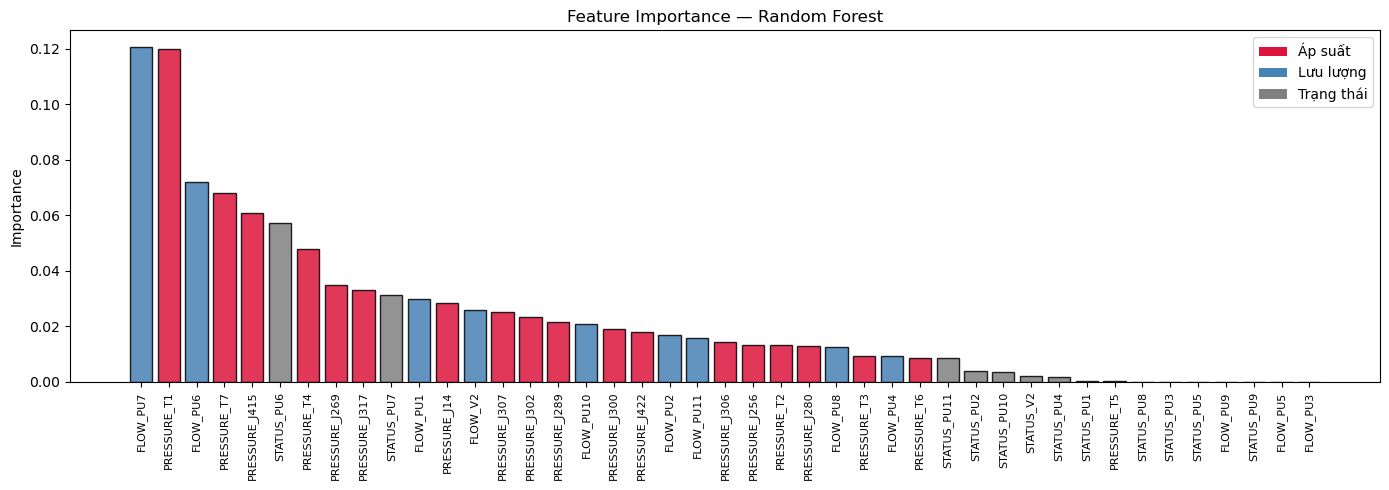


Top 5 đặc trưng quan trọng nhất:
FLOW_PU7         0.120571
PRESSURE_T1      0.119793
FLOW_PU6         0.071778
PRESSURE_T7      0.068005
PRESSURE_J415    0.060675


In [6]:
rf = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1
)
rf.fit(X_tr, y_tr)

y_pred_rf  = rf.predict(X_val)
y_score_rf = rf.predict_proba(X_val)[:, 1]
res = evaluate_model(y_val, y_pred_rf, y_score_rf, 'Random Forest (Val)')
val_results.append(res)

# Feature Importance
feat_imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
colors_bar = ['crimson' if 'PRESSURE' in c else ('steelblue' if 'FLOW' in c else 'gray')
              for c in feat_imp.index]

plt.figure(figsize=(14, 5))
plt.bar(range(len(feat_imp)), feat_imp.values, color=colors_bar, edgecolor='black', alpha=0.85)
plt.xticks(range(len(feat_imp)), feat_imp.index, rotation=90, fontsize=8)
plt.ylabel('Importance')
plt.title('Feature Importance — Random Forest')
legend_elements = [Patch(facecolor='crimson', label='Áp suất'),
                   Patch(facecolor='steelblue', label='Lưu lượng'),
                   Patch(facecolor='gray', label='Trạng thái')]
plt.legend(handles=legend_elements)
plt.tight_layout(); plt.show()
print(f'\nTop 5 đặc trưng quan trọng nhất:\n{feat_imp.head().to_string()}')

## Phần 6: Gradient Boosting

In [7]:
gbc = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42
)
gbc.fit(X_tr, y_tr)

y_pred_gbc  = gbc.predict(X_val)
y_score_gbc = gbc.predict_proba(X_val)[:, 1]
res = evaluate_model(y_val, y_pred_gbc, y_score_gbc, 'Gradient Boosting (Val)')
val_results.append(res)


=== Gradient Boosting (Val) ===
  F1 (macro): 0.9706 | Precision: 0.9853 | Recall: 0.9119
  AUC-ROC  : 0.9915
  TN=4932, FP=8, FN=52, TP=538


## Phần 7: So sánh tổng hợp (Validation)


=== BẢNG SO SÁNH (VALIDATION) ===
                               f1  precision  recall     auc
name                                                        
Random Forest (Val)        0.9749     0.9982  0.9153  0.9976
Gradient Boosting (Val)    0.9706     0.9853  0.9119  0.9915
Logistic Regression (Val)  0.8365     0.5942  0.9034  0.9735


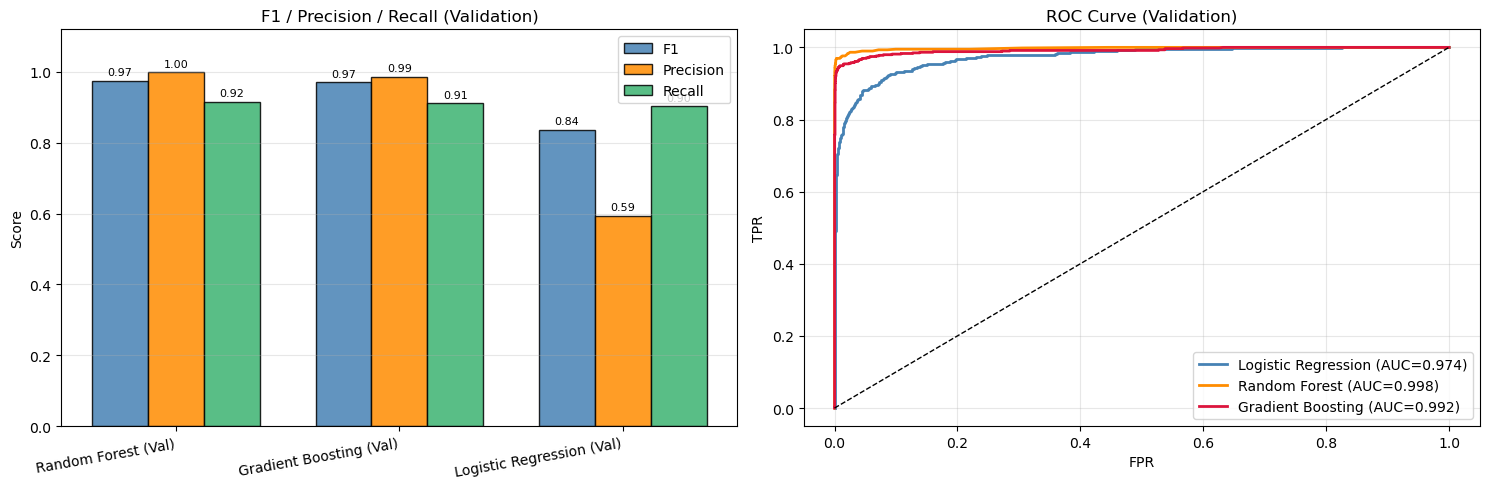

In [8]:
val_df = pd.DataFrame(val_results).set_index('name').sort_values('f1', ascending=False)
print('\n=== BẢNG SO SÁNH (VALIDATION) ===')
print(val_df[['f1','precision','recall','auc']].round(4).to_string())

metrics = ['f1', 'precision', 'recall']
x = np.arange(len(val_df))
width = 0.25
bar_colors = ['steelblue', 'darkorange', 'mediumseagreen']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
for i, (m, c) in enumerate(zip(metrics, bar_colors)):
    bars = ax.bar(x + i*width, val_df[m], width, label=m.capitalize(), color=c,
                  edgecolor='black', alpha=0.85)
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.01,
                f'{b.get_height():.2f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x + width)
ax.set_xticklabels(val_df.index, rotation=10, ha='right')
ax.set_ylabel('Score'); ax.set_ylim(0, 1.12)
ax.set_title('F1 / Precision / Recall (Validation)'); ax.legend()
ax.grid(True, alpha=0.3, axis='y')

ax2 = axes[1]
all_scores_val = {
    'Logistic Regression': y_score_lr,
    'Random Forest':       y_score_rf,
    'Gradient Boosting':   y_score_gbc
}
roc_colors = ['steelblue', 'darkorange', 'crimson']
for (name, sc), color in zip(all_scores_val.items(), roc_colors):
    fpr, tpr, _ = roc_curve(y_val, sc)
    auc = roc_auc_score(y_val, sc)
    ax2.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC={auc:.3f})')
ax2.plot([0,1],[0,1],'k--', linewidth=1)
ax2.set_xlabel('FPR'); ax2.set_ylabel('TPR')
ax2.set_title('ROC Curve (Validation)'); ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

## Phần 8: Đánh giá trên Test 2 (Held-out)

=== KẾT QUẢ TRÊN TEST 2 (HELD-OUT) ===

=== Logistic Regression (Test2) ===
  F1 (macro): 0.6408 | Precision: 0.4749 | Recall: 0.3139
  AUC-ROC  : 0.6017
  TN=7888, FP=565, FN=1117, TP=511

=== Random Forest (Test2) ===
  F1 (macro): 0.6363 | Precision: 0.9855 | Recall: 0.2082
  AUC-ROC  : 0.8456
  TN=8448, FP=5, FN=1289, TP=339

=== Gradient Boosting (Test2) ===
  F1 (macro): 0.7288 | Precision: 0.9712 | Recall: 0.3526
  AUC-ROC  : 0.7714
  TN=8436, FP=17, FN=1054, TP=574


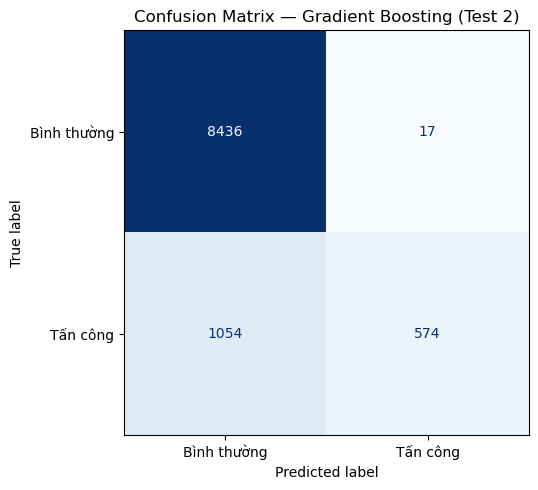

In [9]:
print('=== KẾT QUẢ TRÊN TEST 2 (HELD-OUT) ===')
test2_results = []

for name, model in [('Logistic Regression', lr),
                    ('Random Forest', rf),
                    ('Gradient Boosting', gbc)]:
    y_pred  = model.predict(X_test2_scaled)
    y_score = model.predict_proba(X_test2_scaled)[:, 1]
    res = evaluate_model(y_test2, y_pred, y_score, f'{name} (Test2)')
    test2_results.append(res)

# Confusion matrix cho mô hình tốt nhất
best_name = pd.DataFrame(test2_results).sort_values('f1', ascending=False).iloc[0]['name'].split(' (')[0]
best_model = {'Logistic Regression': lr, 'Random Forest': rf, 'Gradient Boosting': gbc}[best_name]
y_pred_best = best_model.predict(X_test2_scaled)

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test2, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=['Bình thường', 'Tấn công']).plot(
    ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Confusion Matrix — {best_name} (Test 2)')
plt.tight_layout(); plt.show()

## Kết luận Demo

| Mô hình | Ưu điểm | Nhược điểm |
|---|---|---|
| Logistic Regression | Nhanh, dễ giải thích, ít tham số | Chỉ nắm bắt quan hệ tuyến tính |
| Random Forest | Chính xác cao, feature importance, robust | Chậm hơn, khó giải thích |
| Gradient Boosting | Thường F1 tốt nhất, linh hoạt | Cần điều chỉnh hyperparameter |

**Bài học chính:**
- Học máy **có giám sát** đạt F1 cao hơn đáng kể so với không giám sát (Bài B3)
- **Random Forest** và **Gradient Boosting** thường vượt trội
- Các cảm biến **áp suất** và **lưu lượng** thường là đặc trưng quan trọng nhất

---
**Bước tiếp theo:** Mở `b1_ml_batadal_exercise.ipynb` và tự điền vào các ô `???`.